# Lending Game — Part 7: Testing the pricing rules against competitor scenarios

Part 6 tuned our pricing rules on the **training set** against six competitor scenarios. Here every
tuned rule, with its parameters **fixed** (no re-tuning), is scored on the **validation set**
(20,000 loans the rules never saw) against:

* the six tuning scenarios T1–T6;
* **held-out scenarios** the rules were not tuned on: other margins, asymmetric competitors, a
  larger markup, competitors who know less or more than we assumed, and **strategic** competitors
  who use one of our own rules.

Then we choose the rule to submit, following the plan (`report/06_pricing_plan.md`, Part 7):

1. profit and regret tables;
2. three criteria (minimax regret is the main one);
3. a paired bootstrap to check whether the winner is really better;
4. random-mode simulations to see the spread of profit.

All simulations use `simulate_market(mode="expected")` unless stated otherwise. Profits are on the
20,000 validation loans; the real round has 100,000 applicants (about ×5).

## 0. Setup and loading the tuned rules

In [1]:
import sys
sys.path.append("..")  # make src/ importable from analysis/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import SEED
from src.pricing_rules import (load_pricing_data, load_tuned, load_tuned_rules, part7_scenarios,
                               make_scenario, score_rules, regret_table, decision_criteria,
                               bootstrap_diff, random_mode_profits, save_final_rule)
from src import model_plots as mp
from src import pricing_plots as pp

mp.set_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

train = load_pricing_data("train")            # only needed to rebuild R7's competitor model
validation = load_pricing_data("validation")  # the data every rule is scored on

rules = load_tuned_rules(train)               # dict: rule name -> function(data) -> our rates
CARRIED = ["R4+C", "R7+C", "R3", "R2", "R1", "B0"]   # carried from Part 6
ALL_RULES = CARRIED + [r for r in rules if r not in CARRIED]

for name in ALL_RULES:
    shown = {k: (np.round(v, 4).tolist() if isinstance(v, list) else v)
             for k, v in rules[name].params.items() if k not in ("edges", "centres")}
    print(f"{name:<5} {shown}")

R4+C  {'floor': 0.005, 'margins': [0.0175, 0.0175, 0.02, 0.0317, 0.0317, 0.0317, 0.1688, 0.1688, 0.1938, 0.1938], 'cutoff': 0.125}
R7+C  {'delta': -0.02, 'q': 0.5, 'a': 0.4, 'floor': 0.005, 'cutoff': 0.1}
R3    {'a': 0.35, 'm': 0.01, 'floor': 0.02}
R2    {'k': 0.7, 'floor': 0.02}
R1    {'m': 0.04, 'floor': 0.005}
B0    {'floor': 0.02}
R4    {'floor': 0.005, 'margins': [0.0175, 0.0175, 0.02, 0.0317, 0.0317, 0.0317, 0.1688, 0.1688, 0.1938, 0.1938]}
R5    {'m0': 0.035, 'm1': 0.02, 'm2': 0.08, 'floor': 0.005}
R6    {'m0': 0.0475, 'm1': -0.7, 'floor': 0.005}
R7    {'delta': -0.02, 'q': 0.5, 'a': 0.4, 'floor': 0.005}


**Using a rule.** Each loaded rule is a function of the data: `rules["R4+C"](validation)` returns our
rate for each applicant, indexed by `row_id`, with `NaN` where we make no offer. That is the `r3`
column of the offers table `simulate_market` takes. R4 is rebuilt from its saved decile margins; R7
refits its competitor model on the training set exactly as in Part 6. In Part 6 the loaded rules
reproduced every training-set profit to the euro.

In [2]:
rates = {name: rules[name](validation) for name in ALL_RULES}

overview = pd.DataFrame({name: {"offers made": rates[name].notna().mean(),
                                "median rate offered": rates[name].median(),
                                "mean rate offered": rates[name].mean()}
                         for name in ALL_RULES}).T
display(overview.style.format("{:.2%}"))

,offers made,median rate offered,mean rate offered
R4+C,65.30%,8.14%,9.64%
R7+C,55.25%,6.49%,7.48%
R3,99.83%,14.49%,17.86%
R2,99.56%,16.08%,20.02%
R1,100.00%,13.54%,15.97%
B0,100.00%,9.54%,12.13%
R4,99.94%,12.70%,20.70%
R5,100.00%,13.56%,17.25%
R6,99.97%,13.57%,16.68%
R7,99.77%,14.17%,17.92%


On the validation set, the two cutoff rules make offers to only part of the market: **R4+C to 65%**
of applicants and **R7+C to 55%**. Every other rule makes offers to almost everyone.

R4's median rate (12.7%) is close to the others', but its mean (20.7%) is the highest: it quotes
very high rates (17–19 points over break-even) to the riskiest applicants instead of refusing them.
That single difference between R4 and R4+C turns out to decide Part 7.

## 1. Scenario grid

**Tuning scenarios** (as in Part 6, now on validation): T1–T3 break-even + 0/2/4 points, T4–T5
markups of 15%/35%, T6 the average margins of the best-response cycle (4.25 / 3.75 points).

**Held-out scenarios** (never used in tuning):

| group | scenario | competitors |
|---|---|---|
| margin | H1, H3, H5 | break-even + 1, 3, 5 points |
| asymmetric | A05, A13 | lender 1 / lender 2 at (+0, +5) and (−1, +3) points |
| markup | K50 | break-even × 1.5 |
| information | IPUB | use only public information (`p_public`), +2 points: they know less than we assumed |
| information | IFULL | use all three signals (`p_full`), +2 points: they know more |
| strategic | S_R4C | both competitors apply our Part 6 recommendation **R4+C** to their own $p$ |
| strategic | S_R4 | both competitors apply **R4** (the same margins, without the cutoff) to their own $p$ |

The plan's strategic scenario is "competitors use our final rule". Since that rule is what we are
choosing, both candidate shapes are included. R7 cannot be used by the competitors in the same way:
its forecast is built on our own information.

In [3]:
T6_MARGINS = load_tuned()["equilibrium"]["T6_margins"]
scenarios, info = part7_scenarios(validation, T6_MARGINS, strategic_rule=rules["R4+C"],
                                  strategic_name="S_R4C")
scenarios["S_R4"] = make_scenario("rule", validation, rule=rules["R4"], rule_params={})
info.loc["S_R4"] = ["held-out", "strategic: both competitors use R4 (no cutoff)"]
TUNING = [s for s in scenarios if info.loc[s, "group"] == "tuning"]
HELD_OUT = [s for s in scenarios if info.loc[s, "group"] == "held-out"]

info["lender 1 median rate"] = [scenarios[s][0].median() for s in scenarios]
info["lender 2 median rate"] = [scenarios[s][1].median() for s in scenarios]
info["no offer from either competitor"] = [(scenarios[s][0].isna() & scenarios[s][1].isna()).mean()
                                           for s in scenarios]
display(info.style.format({"lender 1 median rate": "{:.2%}", "lender 2 median rate": "{:.2%}",
                           "no offer from either competitor": "{:.1%}"}))

,group,description,lender 1 median rate,lender 2 median rate,no offer from either competitor
T1,tuning,margin 0 (break-even),9.62%,9.65%,0.0%
T2,tuning,margin +2 pts,11.62%,11.65%,0.0%
T3,tuning,margin +4 pts,13.62%,13.65%,0.0%
T4,tuning,markup 15%,11.07%,11.10%,0.0%
T5,tuning,markup 35%,12.97%,13.02%,0.0%
T6,tuning,best-response cycle: +4.25 / +3.75 pts,13.87%,13.40%,0.0%
H1,held-out,margin +1 pt,10.62%,10.65%,0.0%
H3,held-out,margin +3 pts,12.62%,12.65%,0.0%
H5,held-out,margin +5 pts,14.62%,14.65%,0.0%
A05,held-out,"asymmetric: lender 1 +0, lender 2 +5 pts",9.62%,14.65%,0.0%


* **Most scenarios leave no applicant without a competitor offer.** The exception is **S_R4C**: when
  both competitors use R4+C (no offer from $p = 0.125$ by *their own* estimate), **27.8% of
  applicants get no competitor offer at all**. For them, ours is the only offer, and under the game
  rules they take it at any rate up to 100%.
* **The two information scenarios behave as expected.**
  * IPUB: competitors who use only public information are less selective, with a median rate of 12.2%.
  * IFULL: competitors who see all three signals separate risk better, with a median rate of 10.6% and
    a few applicants above 50% risk refused.

  IFULL is a stress test rather than a realistic case: in the game no lender can see the other
  lenders' signals.
* The other held-out scenarios cover margins of −1 to +5 points and a 50% markup. Their competitor
  median rates (8.6%–14.6%) bracket the tuning scenarios.

## 2. Scoring every rule against every scenario

Each of the 10 tuned rules against each of the 16 scenarios, on the validation set. For each cell:
profit, loans, market share, profit per loan, average rate, default rate of the loans won and the
winner's-curse gap (observed − predicted default rate on the loans we win).

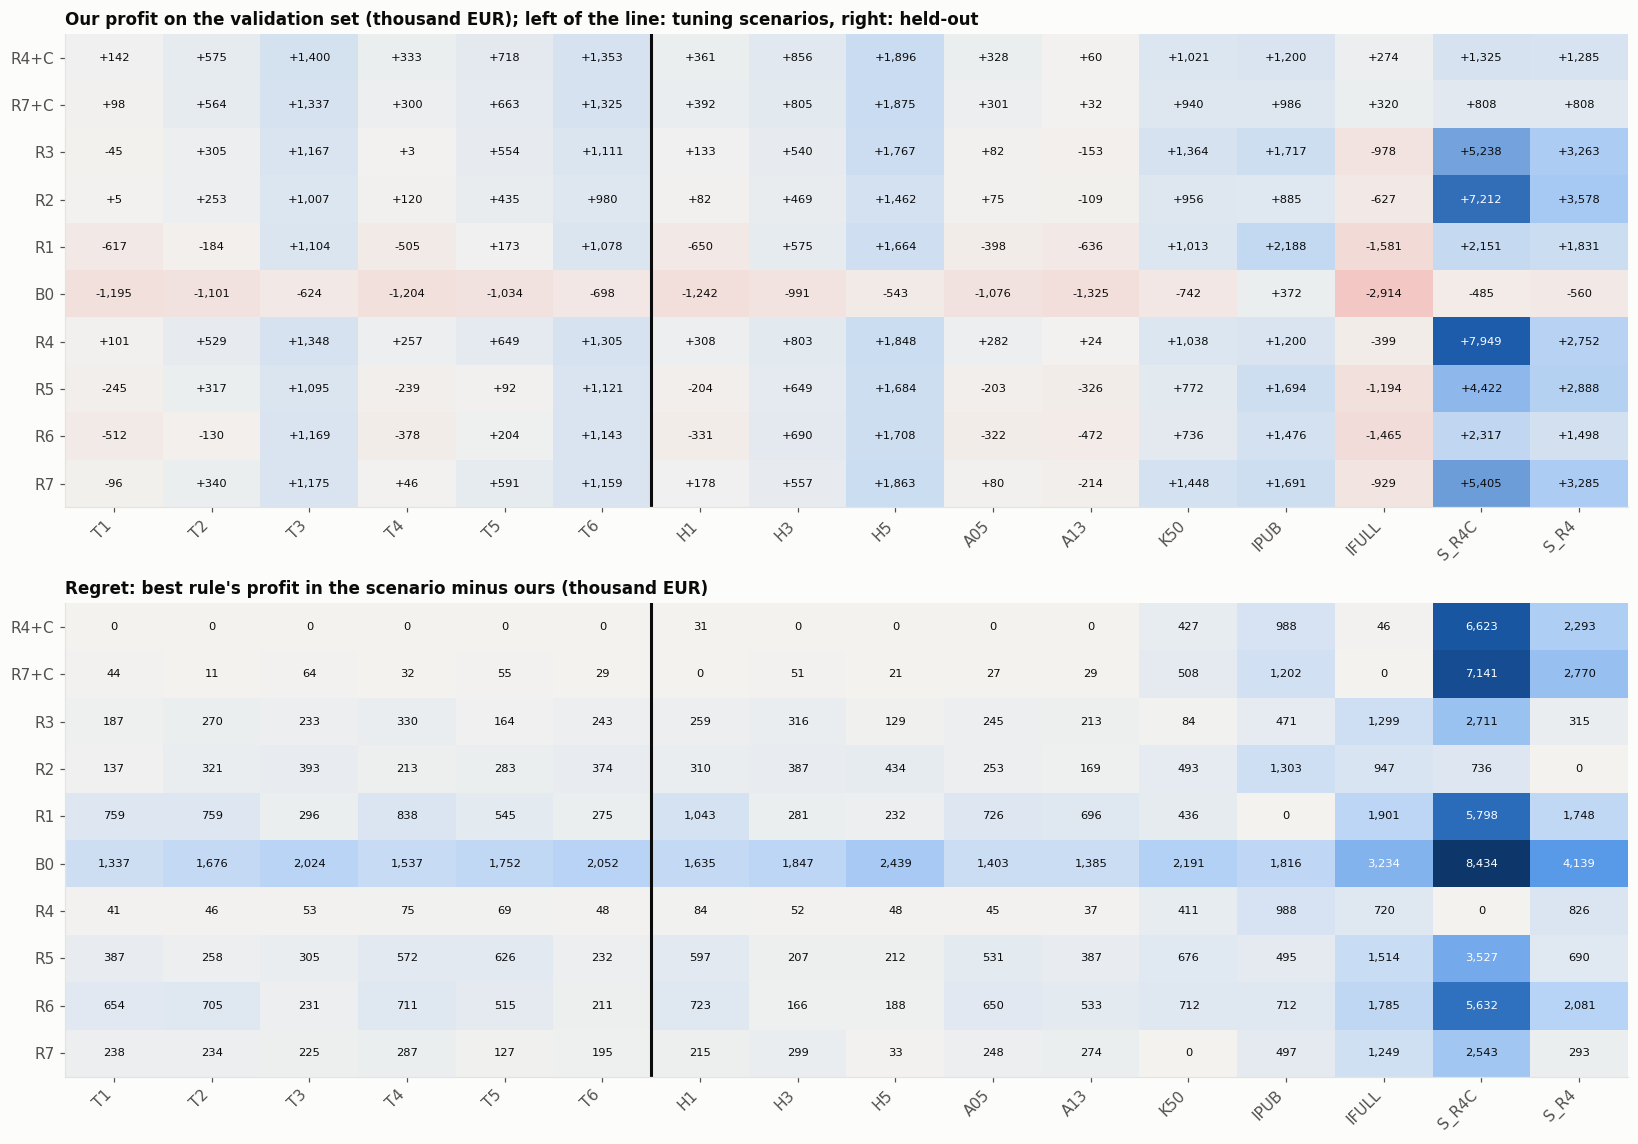

In [4]:
table, profits = score_rules(rates, scenarios, validation)
SCEN_ORDER = TUNING + HELD_OUT

profit = table.pivot(index="rule", columns="scenario", values="profit").loc[ALL_RULES, SCEN_ORDER]
regret = regret_table(profit)

fig, axes = plt.subplots(2, 1, figsize=(15, 10.5))
pp.plot_heatmap(profit, axes[0], "Our profit on the validation set (thousand EUR); "
                "left of the line: tuning scenarios, right: held-out", kind="diverging")
pp.plot_heatmap(regret, axes[1], "Regret: best rule's profit in the scenario minus ours (thousand EUR)",
                kind="sequential", fmt="{:,.0f}")
for ax in axes:
    ax.axvline(len(TUNING) - 0.5, color=mp.INK, lw=2)   # tuning | held-out
fig.tight_layout()
plt.show()

**Profit (top).**

* **The two cutoff rules (R4+C, R7+C) are the only rules profitable in every scenario.**
  * They are best or near-best in all six tuning scenarios and in the margin and asymmetric held-out
    scenarios.
  * Their worst case is A13, a competitor pricing 1 point *below* break-even: +€60k and +€32k.
* **IFULL (competitors know more): every rule without a cutoff loses money**, from −€0.4M (R4) to
  −€2.9M (B0). Only R4+C (+€274k) and R7+C (+€320k) stay profitable. When the competitors know more,
  the risky borrowers we win are the ones they rightly refused or priced high.
* **Strategic scenarios: the cutoff becomes very costly.**
  * In **S_R4C**, the competitors refuse their risky applicants, and every rule that still quotes them
    a price earns a quasi-monopoly profit: **R4 +€7.9M**, R2 +€7.2M, R7 +€5.4M. R4+C makes only
    +€1.3M, because it refuses the same applicants as the competitors.
  * In **S_R4**, the competitors price risky applicants very high instead of refusing them. The rules
    with the most moderate prices on risky applicants win (R2 +€3.6M, R7 +€3.3M, R4 +€2.8M; R4+C
    +€1.3M).
* **IPUB (competitors know less):** everyone does well, even B0 (+€0.4M). The rules with the highest
  margins win (R1 +€2.2M).

**Regret (bottom).** R4+C and R7+C have a regret of at most €0.5M in 13 of the 16 scenarios, but
€1.0–1.2M in IPUB, €2.3–2.8M in S_R4 and **€6.6M and €7.1M in S_R4C**. **R4's regret never exceeds
€1.0M**, at worst in IPUB (€988k), S_R4 (€826k) and IFULL (€720k). R2 comes next (€1.3M at worst);
every other rule has a regret of €2.5M or more somewhere.

**Volume, profit per loan and winner's curse** of the carried rules in a few representative
scenarios: T6 (the most plausible tuning case), H3, IFULL (competitors know more) and the two
strategic scenarios.

In [5]:
SHOW = ["T6", "H3", "IFULL", "S_R4C", "S_R4"]
detail = (table[table["rule"].isin(CARRIED + ["R4", "R7"]) & table["scenario"].isin(SHOW)]
          .set_index(["scenario", "rule"]).loc[SHOW])
display(detail[["profit", "n_loans", "share", "profit_per_loan", "avg_rate", "default_rate_won", "gap"]]
        .style.format({"profit": "{:+,.0f}", "n_loans": "{:,.0f}", "share": "{:.1%}",
                       "profit_per_loan": "{:+,.0f}", "avg_rate": "{:.2%}",
                       "default_rate_won": "{:.2%}", "gap": "{:+.2%}"}, na_rep="no loans"))

* **In ordinary scenarios (T6, H3), R4 and R4+C are almost the same rule.** Same number of loans
  (about 7,400 in T6, 4,750 in H3), same average rate, profit per loan €175–183. R4+C is €48–52k ahead
  because its cutoff avoids a few bad loans (gap +0.4 vs +0.5 point in T6).
* **IFULL:** the risky borrowers R4 wins are clearly adverse. Gap +3.7 points against +1.6 for R4+C;
  default rate 10.4% at an average rate of 12.7%, i.e. −€92 per loan.
* **S_R4C:**
  * R4 wins half of the applicants (10,000 loans) at an average rate of 26%. They default at 13.3%,
    only 0.9 point above our prediction, because there was no competitor to select them: **+€795 per
    loan**.
  * R4+C, which refuses them, wins 5,000 loans at €264 each.
* **The winner's curse shrinks when competitors refuse risky applicants** (gap below 1 point in S_R4C
  for every rule): whoever is the only offer gets an unselected borrower.

## 3. Decision

### 3.1 Three criteria

* **Maximin:** the best worst-case profit over the scenarios.
* **Minimax regret (main criterion):** the smallest worst-case regret. A rule that is never far from
  the best rule of each scenario is robust to not knowing the competitors.
* **Weighted average:** the highest weighted profit. Following the plan, we put **more weight on the
  strategic and the +1 to +3 point scenarios**, and write the weights down here:

| scenarios | weight each | why |
|---|---|---|
| S_R4C, S_R4 (strategic) | 1.5 (3 in total) | competitors who optimise their pricing like we do |
| H1, T2, H3, T6 | 2 | margins of 1–4 points: where best-responding competitors end up (Part 6, 3b) |
| all other scenarios | 1 | plausible but less likely |

The weights are normalised to sum to 1. Each criterion is computed on all 16 scenarios, then on the
held-out scenarios only.

In [6]:
WEIGHTS = {s: 1.0 for s in SCEN_ORDER}
WEIGHTS.update({"S_R4C": 1.5, "S_R4": 1.5, "H1": 2.0, "T2": 2.0, "H3": 2.0, "T6": 2.0})

criteria_all = decision_criteria(profit, WEIGHTS).sort_values("max regret")
criteria_held = decision_criteria(profit[HELD_OUT], WEIGHTS).sort_values("max regret")
fmt = {"worst-case profit": "{:+,.0f}", "max regret": "{:,.0f}", "weighted profit": "{:+,.0f}"}
print("All 16 scenarios (sorted by max regret, the main criterion):")
display(criteria_all.style.format(fmt))
print("Held-out scenarios only:")
display(criteria_held.style.format(fmt))

ranks = pd.DataFrame({"minimax regret": criteria_all["max regret"].rank(),
                      "maximin": (-criteria_all["worst-case profit"]).rank(),
                      "weighted": (-criteria_all["weighted profit"]).rank(),
                      "minimax regret (held-out)": criteria_held["max regret"].rank()}).astype(int)
display(ranks.sort_values("minimax regret"))

All 16 scenarios (sorted by max regret, the main criterion):


,worst-case profit,worst scenario,max regret,max-regret scenario,weighted profit
rule,,,,,
R4,"-399,261",IFULL,"988,037",IPUB,"+1,347,101"
R2,"-626,806",IFULL,"1,302,807",IPUB,"+1,141,160"
R7,"-928,904",IFULL,"2,543,314",S_R4C,"+1,102,864"
R3,"-978,500",IFULL,"2,710,632",S_R4C,"+1,067,099"
R5,"-1,193,813",IFULL,"3,526,664",S_R4C,"+850,497"
R6,"-1,464,917",IFULL,"5,632,023",S_R4C,"+505,173"
R1,"-1,581,082",IFULL,"5,797,506",S_R4C,"+476,935"
R4+C,"+60,403",A13,"6,623,388",S_R4C,"+837,077"
R7+C,"+31,859",A13,"7,140,522",S_R4C,"+735,608"


Held-out scenarios only:


,worst-case profit,worst scenario,max regret,max-regret scenario,weighted profit
rule,,,,,
R4,"-399,261",IFULL,"988,037",IPUB,"+1,712,794"
R2,"-626,806",IFULL,"1,302,807",IPUB,"+1,533,150"
R7,"-928,904",IFULL,"2,543,314",S_R4C,"+1,418,841"
R3,"-978,500",IFULL,"2,710,632",S_R4C,"+1,376,809"
R5,"-1,193,813",IFULL,"3,526,664",S_R4C,"+1,098,554"
R6,"-1,464,917",IFULL,"5,632,023",S_R4C,"+623,102"
R1,"-1,581,082",IFULL,"5,797,506",S_R4C,"+620,915"
R4+C,"+60,403",A13,"6,623,388",S_R4C,"+856,089"
R7+C,"+31,859",A13,"7,140,522",S_R4C,"+713,304"


,minimax regret,maximin,weighted,minimax regret (held-out)
rule,,,,
R4,1,3,1,1
R2,2,4,2,2
R7,3,5,3,3
R3,4,6,4,4
R5,5,7,5,5
R6,6,8,8,6
R1,7,9,9,7
R4+C,8,1,6,8
R7+C,9,2,7,9


**R4 is first on the main criterion and on the weighted criterion, on all scenarios and on the
held-out scenarios alone.**

| | R4 | R4+C | R7+C | R2 |
|---|---|---|---|---|
| max regret (main) | **€0.99M** (rank 1) | €6.62M (rank 8) | €7.14M (rank 9) | €1.30M (rank 2) |
| worst-case profit | −€0.40M, IFULL (rank 3) | **+€0.06M**, A13 (rank 1) | +€0.03M (rank 2) | −€0.63M (rank 4) |
| weighted profit | **+€1.35M** (rank 1) | +€0.84M (rank 6) | +€0.74M (rank 7) | +€1.14M (rank 2) |

* The **cutoff rules win maximin**: they never lose money, in any scenario.
* But **their regret is the largest of all rules except B0**, because of the strategic scenarios.
  Refusing risky applicants is excellent when the competitors lend to them, and very costly when the
  competitors do not.
* **R4 is never far from the best rule in any scenario.** It keeps the same margins as R4+C for 89%
  of applicants, and quotes the riskiest ones a very high price instead of refusing them.

### 3.2 Is the winner really better? Paired bootstrap

We compare the top three rules on the main criterion with each other, and the winner with **R4+C**,
Part 6's recommendation. For each pair, the 20,000 validation applicants are resampled 500 times
(the same resample for both rules) and the profit difference is computed in each scenario and for
the weighted profit. A 95% interval that excludes 0 means the difference is not luck of the
sample.

top three on minimax regret: ['R4', 'R2', 'R7']


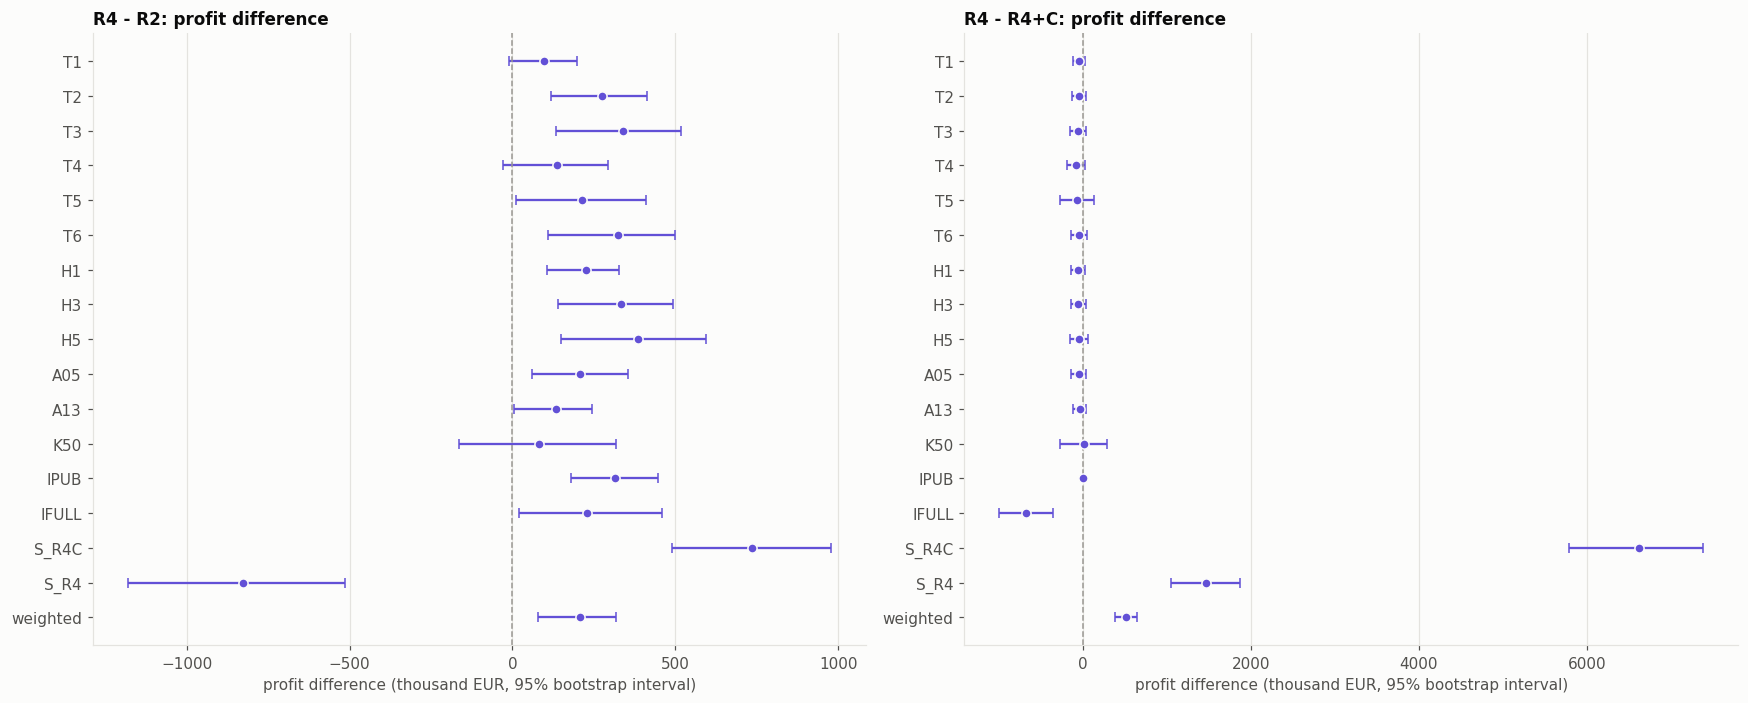

In [7]:
TOP = criteria_all.index[:3].tolist()
print("top three on minimax regret:", TOP)
PAIRS = [(a, b) for i, a in enumerate(TOP) for b in TOP[i + 1:]]
if "R4+C" not in TOP:
    PAIRS.append((TOP[0], "R4+C"))          # the winner against Part 6's recommendation
COMPARED = sorted({r for pair in PAIRS for r in pair}, key=ALL_RULES.index)

w = pd.Series(WEIGHTS)[SCEN_ORDER] / pd.Series(WEIGHTS)[SCEN_ORDER].sum()
weighted_vector = {r: sum(w[s] * profits[(r, s)] for s in SCEN_ORDER) for r in COMPARED}

boot_rows = {}
for a, b in PAIRS:
    if True:
        for s in SCEN_ORDER:
            boot_rows[(f"{a} - {b}", s)] = bootstrap_diff(profits[(a, s)], profits[(b, s)], n=500, seed=SEED)
        boot_rows[(f"{a} - {b}", "weighted")] = bootstrap_diff(weighted_vector[a], weighted_vector[b],
                                                               n=500, seed=SEED)
boot = pd.DataFrame(boot_rows).T
boot.index.names = ["comparison", "scenario"]
boot["significant"] = (boot["lower"] > 0) | (boot["upper"] < 0)
display(boot.style.format({"estimate": "{:+,.0f}", "lower": "{:+,.0f}", "upper": "{:+,.0f}",
                           "share a > b": "{:.0%}"}))

shown = [f"{TOP[0]} - {TOP[1]}"] + ([f"{TOP[0]} - R4+C"] if "R4+C" not in TOP else [])
fig, axes = plt.subplots(1, len(shown), figsize=(8 * len(shown), 6.5), squeeze=False)
for ax, comparison in zip(axes[0], shown):
    pp.plot_bootstrap_intervals(boot.loc[comparison], ax, f"{comparison}: profit difference")
fig.tight_layout()
plt.show()

* **R4 vs R2 (runner-up):** R4 is significantly better in 12 of the 16 scenarios and on weighted profit
  (+€206k, 95% interval [+€79k, +€318k]). The difference is not significant in T1, T4 and K50, and R2 is
  significantly better only in S_R4. **R4's lead is not luck.**
* **R4 vs R7:** R4 is significantly better on weighted profit (+€244k, [+€116k, +€383k]); R7 wins only in
  K50, IPUB and S_R4.
* **R4 vs R4+C (right panel), the real decision:**
  * In 13 of the 16 scenarios the difference is **not significant**, and every interval contains 0.
    R4+C is ahead by €37–75k (3–5% of profit) in 11 of them, R4 is ahead in K50, and they tie in
    IPUB.
  * The difference is significant in only three scenarios, in both directions:
    * **IFULL:** R4 −€673k ([−€991k, −€352k]);
    * **S_R4C:** R4 +€6.62M;
    * **S_R4:** R4 +€1.47M.
  * On weighted profit, R4 is ahead by **+€510k** ([+€386k, +€642k]).

The plan's tie-break ("if the interval contains 0, take the simpler rule") is not needed: on the
criteria, R4's advantage is significant. On the ordinary scenarios R4 and R4+C are statistically
equivalent, and R4 is the simpler of the two (no cutoff).

### 3.3 Random mode: how much does luck matter?

Expected mode averages each borrower's choice over the three preference types. In the real game each
borrower has one type. Random mode draws one type per borrower (and breaks ties at random), here 20
times per rule and scenario. We report the mean and the 5th percentile of our profit for the rules
compared above.

In [8]:
SEEDS = range(20)
rand_rows = {}
for r in COMPARED:
    for s in SCEN_ORDER:
        draws = random_mode_profits(rates[r], scenarios[s], validation, seeds=SEEDS)
        rand_rows[(r, s)] = {"expected mode": profit.loc[r, s], "random mean": draws.mean(),
                             "random 5th pct": np.percentile(draws, 5), "random std": draws.std()}
rand = pd.DataFrame(rand_rows).T
rand.index.names = ["rule", "scenario"]
display(rand.unstack("rule").swaplevel(axis=1).sort_index(axis=1, level=0)
        .style.format("{:+,.0f}"))

* **One draw of the preference types moves our profit by about ±€50–130k** (standard deviation on
  20,000 loans), the same size as the R4 / R4+C differences in ordinary scenarios. Those small
  differences are inside the game's luck.
* **R4's 5th percentile is negative only in A13 (−€40k) and IFULL (−€620k)**; R4+C's only in A13
  (−€6k). In every other scenario, even an unlucky draw leaves both rules profitable.
* The random-mode means are a few percent below expected mode for every rule. That is not a bias: the
  same 20 draws are used for every rule and scenario, so one unlucky set of draws pulls them all down
  together. With 300 draws, R4's random-mode mean in T6 (€1.296M) matches expected mode (€1.305M) within
  1.6 standard errors.

## 4. Final choice

**R4: break-even plus a margin that rises with risk, without a cutoff.**

* **Smallest max regret** (€0.99M, against €1.30M for the next
  rule and €6.6M for R4+C), on all scenarios and on the held-out ones. It also has the highest weighted
  profit.
* **The bootstrap confirms its lead**: over R2 and R7 on weighted profit, and over R4+C.
* **R4 and R4+C differ only on the riskiest applicants** ($p_{own}$ above about 12.5%, a third of the
  market). R4+C refuses them; R4 quotes them 17–19 points over break-even (rates of roughly 30–85%).
  * **If the competitors lend to these borrowers** at reasonable rates (our tuning scenarios and most
    held-out ones), R4's high quotes rarely win. It costs about €40–75k on 20,000 loans (3–5% of
    profit), not statistically significant.
  * **If the competitors refuse them or price them out** (the strategic scenarios), R4 is the only or the
    cheapest lender and earns €1.5–6.6M more. With no competitor to select them, these borrowers are
    much less adverse (gap below 1 point).
  * **R4 loses clearly only if the competitors know more than we do** (IFULL, −€0.67M). That scenario is
    an extreme stress test: it gives both competitors all three signals, which no lender has in the game.
* So R4 keeps an option that is cheap to hold and very valuable if competitors also learn to stay away
  from risky borrowers. Part 3 showed that break-even pricing loses money, so careful competitors may
  well learn this.

The rule is also the simplest of the strong candidates: it uses only `p_own` and a fixed margin curve.
Its parameters are saved to `data/pricing/final_rule.json` for Part 8.

In [9]:
FINAL = "R4"   # the decision above

params = dict(rules[FINAL].params)
notes = (f"Chosen in Part 7 (analysis/competitor_scenarios.ipynb). Validation: max regret "
         f"{criteria_all.loc[FINAL, 'max regret']:,.0f} EUR, worst-case profit "
         f"{criteria_all.loc[FINAL, 'worst-case profit']:+,.0f} EUR, weighted profit "
         f"{criteria_all.loc[FINAL, 'weighted profit']:+,.0f} EUR on 20,000 loans. "
         f"Rebuild with load_tuned_rules(train)['{FINAL}'].")
path = save_final_rule(FINAL, params, notes)
print(f"saved {path}")
print(f"final rule: {FINAL}")
print({k: v for k, v in params.items() if k != "edges"})

saved /Users/kenzachaabouni/Documents/MSC_M2/intro-finance/LendingGame_Lender3_Round1/Lending-Game/data/pricing/final_rule.json
final rule: R4
{'floor': 0.005, 'centres': [0.00528012992564965, 0.01966243357343165, 0.0358029324211695, 0.0542164159133189, 0.0753354734398568, 0.09861224861761686, 0.1232345023098893, 0.14090826676618684, 0.1774464593593158, 0.2507941100730716], 'margins': [0.0175, 0.0175, 0.02, 0.03166666666666667, 0.03166666666666667, 0.03166666666666667, 0.16875, 0.16875, 0.19375, 0.19375]}


## 5. Summary and conclusion


**What we did.** The ten rules tuned in Part 6 were scored, with fixed parameters, on the 20,000
validation loans against:

* the six tuning scenarios;
* ten held-out scenarios: other margins, asymmetric competitors, a 50% markup, competitors who know
  less or more, and competitors who use our own rules.

Rules were compared on minimax regret (the main criterion), maximin and a weighted average, with a
paired bootstrap and random-mode simulations.

**Results.**

| rule | max regret | worst case | weighted profit | profitable in every scenario |
|---|---|---|---|---|
| **R4** | **€0.99M** | −€0.40M (IFULL) | **+€1.35M** | no (IFULL) |
| R2 | €1.30M | −€0.63M (IFULL) | +€1.14M | no |
| R7 | €2.54M | −€0.93M (IFULL) | +€1.10M | no |
| R4+C | €6.62M | **+€0.06M** | +€0.84M | **yes** |
| R7+C | €7.14M | +€0.03M | +€0.74M | yes |
| B0 | €8.43M | −€2.91M | −€0.95M | no |

Profits on 20,000 validation loans; the real round has 100,000 applicants (about ×5).

**Conclusions.**

1. **The tuned rules generalise.** On validation and on held-out scenarios, the ranking of Part 6
   holds in the ordinary scenarios. R4+C and R7+C are still the best when the competitors behave like
   our tuning scenarios.
2. **The cutoff is the key decision.** Refusing the riskiest third of applicants protects us when
   competitors lend to them, or know more than we do. It costs us a lot when competitors stay away
   from them, as rational competitors aware of the winner's curse may well do.
3. **R4, with high prices instead of refusals, is the robust choice.** It has the smallest worst-case
   regret, the highest weighted profit, and is statistically equivalent to R4+C in ordinary scenarios.
4. **Final rule: R4.**
   * $r = be(p_{own}) + m(p_{own})$, floor 0.5%;
   * $m(p)$ about 1.75 points for $p_{own} < 2.75\%$, 2 points up to 4.5%, 3.2 points up to 11%, and
     17–19 points above;
   * no offer when $p \ge 0.5$ or when the rate would exceed 100%.

   Saved in `data/pricing/final_rule.json`; rebuilt with `load_tuned_rules(train)["R4"]`.

**Caveats.**

* **The decision rests on the strategic scenarios.** If we were sure the competitors lend to all
  applicants at reasonable rates, R4+C would be marginally better (by €40–75k on 20,000 loans, not
  significant).
* The scenario weights and the choice of strategic scenarios are judgement calls, and the competitors
  are our reconstruction.